# AgroVision AI — Complete Deep Learning Development Notebook

This notebook consolidates dataset inspection, preprocessing, EfficientNetB0 transfer learning, training, evaluation, testing, and model export into one VS Code Jupyter Notebook.

**Existing project assumptions preserved:** 38 PlantVillage classes, 224×224 RGB input, EfficientNetB0 pretrained on ImageNet, and model output at `saved_model/best_model.keras`.

> Before running, set `DATASET_DIR` below to the folder containing the 38 class subfolders (for example `dataset/PlantVillage`). Training may take a while. Run the notebook cells in order. This notebook does not invent evaluation results; metrics are calculated only after you run the cells.

## 1. Imports and configuration

In [3]:
from pathlib import Path
import os, json, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

SEED = 42
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 30
VALIDATION_FRACTION = 0.15
TEST_FRACTION = 0.15
DATASET_DIR = Path("dataset/PlantVillage")  # Change this if your dataset is elsewhere
MODEL_DIR = Path("saved_model")
OUTPUT_DIR = Path("outputs")
PLOT_DIR = OUTPUT_DIR / "plots"
HISTORY_DIR = OUTPUT_DIR / "history"

for folder in [MODEL_DIR, OUTPUT_DIR, PLOT_DIR, HISTORY_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Python notebook environment ready")
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Visible GPU devices:", tf.config.list_physical_devices("GPU"))
print("Dataset path:", DATASET_DIR.resolve())

Python notebook environment ready
TensorFlow: 2.21.0
NumPy: 2.4.6
Visible GPU devices: []
Dataset path: C:\Users\narai\OneDrive\Desktop\Agro Vision\AgroVision\dataset\PlantVillage


## 2. Check dataset structure and class counts

In [4]:
if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR.resolve()}\n"
        "Set DATASET_DIR to the directory whose immediate subfolders are class names."
    )

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_dirs = sorted([p for p in DATASET_DIR.iterdir() if p.is_dir()])
if not class_dirs:
    raise ValueError(f"No class subfolders found inside {DATASET_DIR}")

class_names = [p.name for p in class_dirs]
class_to_index = {name: i for i, name in enumerate(class_names)}

records = []
for class_name in class_names:
    for path in (DATASET_DIR / class_name).rglob("*"):
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append({"filepath": str(path), "class_name": class_name, "label": class_to_index[class_name]})

df = pd.DataFrame(records)
if df.empty:
    raise ValueError("No supported image files found in the dataset.")

print(f"Images found: {len(df):,}")
print(f"Classes found: {len(class_names)}")
display(df.groupby("class_name").size().rename("image_count").to_frame())

Images found: 54,305
Classes found: 38


,image_count
class_name,
Apple___Apple_scab,630
Apple___Black_rot,621
Apple___Cedar_apple_rust,275
Apple___healthy,1645
Blueberry___healthy,1502
Cherry_(including_sour)___Powdery_mildew,1052
Cherry_(including_sour)___healthy,854
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot,513
Corn_(maize)___Common_rust_,1192


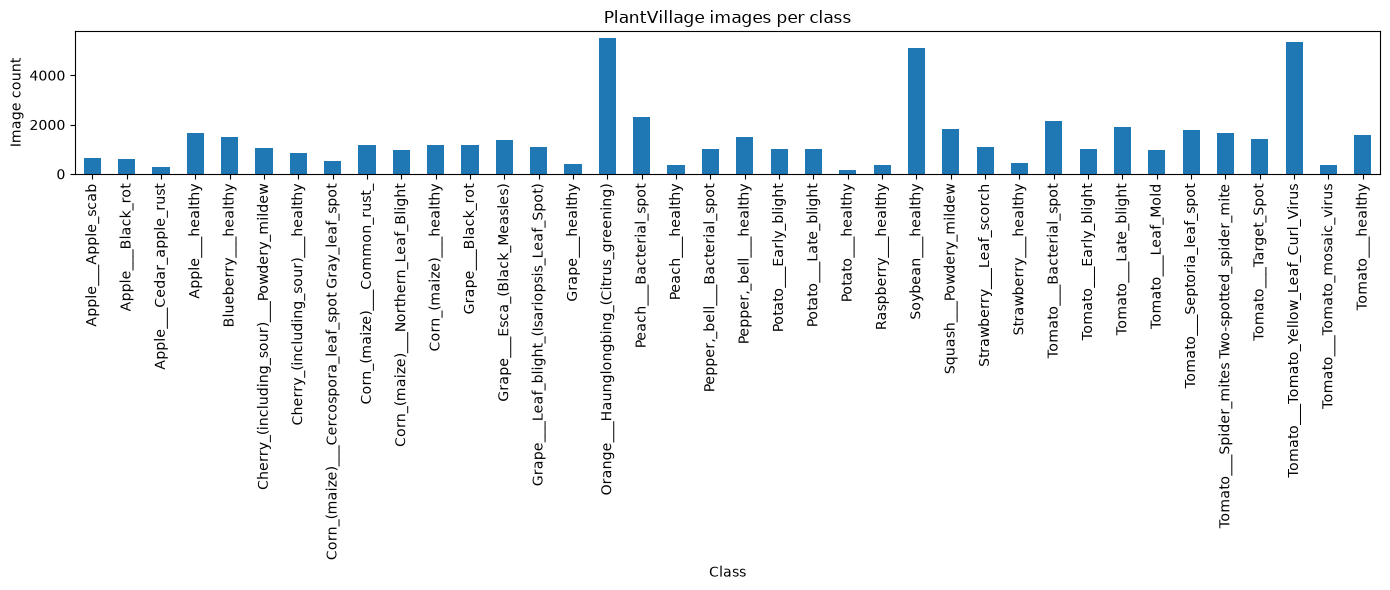

In [5]:
plt.figure(figsize=(14, 6))
df["class_name"].value_counts().sort_index().plot(kind="bar")
plt.title("PlantVillage images per class")
plt.xlabel("Class")
plt.ylabel("Image count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 3. Validate a sample of images and visualize examples

Unreadable images: 0


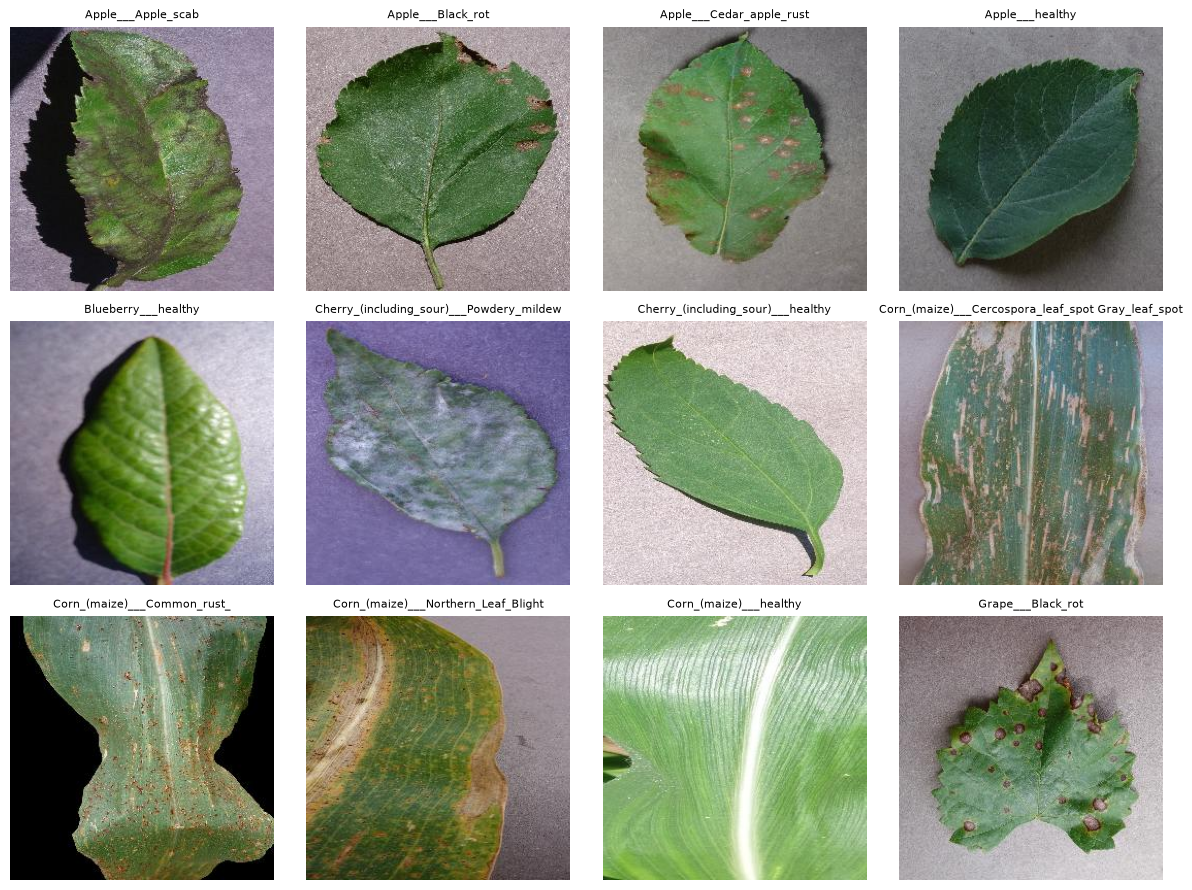

In [6]:
# Verify every file is readable. This can take a little time for a large dataset.
bad_files = []
for path in df["filepath"]:
    try:
        with Image.open(path) as im:
            im.verify()
    except Exception:
        bad_files.append(path)

print("Unreadable images:", len(bad_files))
if bad_files:
    print("First unreadable paths:", bad_files[:10])
    df = df[~df["filepath"].isin(bad_files)].reset_index(drop=True)
    # Rebuild labels after removing invalid files
    class_names = sorted(df["class_name"].unique().tolist())
    class_to_index = {name: i for i, name in enumerate(class_names)}
    df["label"] = df["class_name"].map(class_to_index)

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
sample_df = df.groupby("class_name", group_keys=False).sample(n=1, random_state=SEED).head(12)
for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    with Image.open(row["filepath"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(row["class_name"], fontsize=8)
    ax.axis("off")
for ax in list(axes.flat)[len(sample_df):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Stratified train / validation / test split

In [7]:
# Keep the test set separate from model fitting and tuning.
train_val_df, test_df = train_test_split(
    df, test_size=TEST_FRACTION, random_state=SEED, stratify=df["label"]
)
relative_val_fraction = VALIDATION_FRACTION / (1.0 - TEST_FRACTION)
train_df, val_df = train_test_split(
    train_val_df, test_size=relative_val_fraction, random_state=SEED, stratify=train_val_df["label"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"Train: {len(train_df):,} ({len(train_df)/len(df):.1%})")
print(f"Validation: {len(val_df):,} ({len(val_df)/len(df):.1%})")
print(f"Test: {len(test_df):,} ({len(test_df)/len(df):.1%})")
print("Class mapping (the order must be preserved at inference):")
for i, name in enumerate(class_names):
    print(i, name)

# Save the class mapping used by this exact model. The Streamlit prediction module imports this file.
class_names_payload = {"class_names": class_names, "image_size": list(IMAGE_SIZE)}
(MODEL_DIR / "class_names.json").write_text(json.dumps(class_names_payload, indent=2), encoding="utf-8")
class_names_py = "CLASS_NAMES = " + repr(class_names) + "\n"
Path("class_names.py").write_text(class_names_py, encoding="utf-8")
print("Saved class_names.json and synchronized class_names.py")

Train: 38,013 (70.0%)
Validation: 8,146 (15.0%)
Test: 8,146 (15.0%)
Class mapping (the order must be preserved at inference):
0 Apple___Apple_scab
1 Apple___Black_rot
2 Apple___Cedar_apple_rust
3 Apple___healthy
4 Blueberry___healthy
5 Cherry_(including_sour)___healthy
6 Cherry_(including_sour)___Powdery_mildew
7 Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 Corn_(maize)___Common_rust_
9 Corn_(maize)___healthy
10 Corn_(maize)___Northern_Leaf_Blight
11 Grape___Black_rot
12 Grape___Esca_(Black_Measles)
13 Grape___healthy
14 Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
15 Orange___Haunglongbing_(Citrus_greening)
16 Peach___Bacterial_spot
17 Peach___healthy
18 Pepper,_bell___Bacterial_spot
19 Pepper,_bell___healthy
20 Potato___Early_blight
21 Potato___healthy
22 Potato___Late_blight
23 Raspberry___healthy
24 Soybean___healthy
25 Squash___Powdery_mildew
26 Strawberry___healthy
27 Strawberry___Leaf_scorch
28 Tomato___Bacterial_spot
29 Tomato___Early_blight
30 Tomato___healthy
31 Tomato_

## 5. Preprocessing and `tf.data` pipelines

The original project passes pixel values in the 0–255 range to the Keras EfficientNetB0 model. Keras EfficientNet includes its own input rescaling/preprocessing, so **do not divide images by 255 a second time**. Keep the same convention in training and `predict.py`.

In [8]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_resize(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SIZE)
    # EfficientNetB0 Keras application expects float pixel values in [0, 255].
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.int32)

def make_dataset(frame, training=False):
    paths = frame["filepath"].astype(str).to_numpy()
    labels = frame["label"].astype(np.int32).to_numpy()
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(min(len(frame), 5000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(decode_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds

train_dataset = make_dataset(train_df, training=True)
validation_dataset = make_dataset(val_df)
test_dataset = make_dataset(test_df)

for images, labels in train_dataset.take(1):
    print("Batch image shape:", images.shape)
    print("Batch label shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

Batch image shape: (32, 224, 224, 3)
Batch label shape: (32,)
Pixel range: 0.0 to 255.0


## 6. Build EfficientNetB0 transfer-learning model

In [9]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB0

NUM_CLASSES = len(class_names)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),
    layers.RandomContrast(0.10),
], name="data_augmentation")

base_model = EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3)
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(IMAGE_SIZE[0], IMAGE_SIZE[1], 3), name="leaf_image")
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D(name="global_average_pooling2d")(x)
x = layers.Dropout(0.3, name="dropout")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="dense")(x)
model = Model(inputs, outputs, name="AgroVision_EfficientNetB0")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Exception: URL fetch failure on https://storage.googleapis.com/keras-applications/efficientnetb0_notop.h5: None -- [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: self-signed certificate in certificate chain (_ssl.c:1006)

## 7. Train and save the best model

In [ ]:
best_model_path = MODEL_DIR / "best_model.keras"
final_model_path = MODEL_DIR / "final_model.keras"
history_csv = HISTORY_DIR / "training_history.csv"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    ),
    tf.keras.callbacks.CSVLogger(str(history_csv))
]

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

model.save(final_model_path)
print("Best checkpoint:", best_model_path.resolve())
print("Final model:", final_model_path.resolve())

## 8. Plot training curves

In [ ]:
history_df = pd.DataFrame(history.history)
display(history_df.tail())

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history.history.get("accuracy", []), label="Training accuracy")
ax.plot(history.history.get("val_accuracy", []), label="Validation accuracy")
ax.set_title("AgroVision — Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(PLOT_DIR / "accuracy.png", dpi=150)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history.history.get("loss", []), label="Training loss")
ax.plot(history.history.get("val_loss", []), label="Validation loss")
ax.set_title("AgroVision — Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(PLOT_DIR / "loss.png", dpi=150)
plt.show()

## 9. Final held-out test evaluation

In [ ]:
# Reload the best checkpoint for final evaluation, rather than evaluating the last epoch blindly.
best_model = tf.keras.models.load_model(best_model_path)
test_loss, test_accuracy = best_model.evaluate(test_dataset, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")

In [ ]:
y_true = np.concatenate([labels.numpy() for _, labels in test_dataset], axis=0)
probabilities = best_model.predict(test_dataset, verbose=1)
y_pred = np.argmax(probabilities, axis=1)

print(classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))
report = classification_report(
    y_true, y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)
pd.DataFrame(report).transpose().to_csv(OUTPUT_DIR / "classification_report.csv")

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(len(class_names))))
fig, ax = plt.subplots(figsize=(18, 16))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=90, colorbar=False, values_format="d")
plt.title("AgroVision — Test Confusion Matrix")
plt.tight_layout()
plt.savefig(PLOT_DIR / "confusion_matrix.png", dpi=150)
plt.show()

## 10. Inspect incorrect predictions and top-3 outputs

In [ ]:
test_results = test_df.copy()
test_results["true_label"] = y_true
test_results["pred_label"] = y_pred
test_results["true_class"] = [class_names[i] for i in y_true]
test_results["predicted_class"] = [class_names[i] for i in y_pred]
test_results["confidence_percent"] = probabilities.max(axis=1) * 100
errors = test_results[test_results["true_label"] != test_results["pred_label"]]
print(f"Misclassified test images: {len(errors)} / {len(test_results)}")
display(errors[["filepath", "true_class", "predicted_class", "confidence_percent"]].head(25))

# Display a small sample of mistakes for visual inspection.
n_show = min(12, len(errors))
if n_show:
    examples = errors.sample(n=n_show, random_state=SEED)
    fig, axes = plt.subplots(3, 4, figsize=(14, 10))
    for ax, (_, row) in zip(axes.flat, examples.iterrows()):
        with Image.open(row["filepath"]) as im:
            ax.imshow(im.convert("RGB"))
        ax.set_title(f"True: {row['true_class']}\nPred: {row['predicted_class']}\n{row['confidence_percent']:.1f}%", fontsize=7)
        ax.axis("off")
    for ax in list(axes.flat)[n_show:]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [ ]:
def predict_path(image_path, model_to_use=best_model, top_k=3):
    image = tf.keras.utils.load_img(image_path, target_size=IMAGE_SIZE, color_mode="rgb")
    array = tf.keras.utils.img_to_array(image).astype(np.float32)
    # Keep raw [0,255] pixel convention for Keras EfficientNetB0.
    probs = model_to_use.predict(np.expand_dims(array, axis=0), verbose=0)[0]
    top_indices = np.argsort(probs)[::-1][:top_k]
    return [
        {"class_name": class_names[int(i)], "confidence_percent": float(probs[i] * 100)}
        for i in top_indices
    ]

# Change this to an image path to test a single file.
SAMPLE_IMAGE_PATH = None  # Example: "test_images/potato1.jpg"
if SAMPLE_IMAGE_PATH and Path(SAMPLE_IMAGE_PATH).exists():
    display(Image.open(SAMPLE_IMAGE_PATH))
    print(predict_path(SAMPLE_IMAGE_PATH))
else:
    print("Set SAMPLE_IMAGE_PATH to a local image to test single-image inference.")

## 11. Export and verify inference compatibility

In [ ]:
# Save class ordering for the separate Streamlit inference module.
(MODEL_DIR / "class_names.json").write_text(
    json.dumps({"class_names": class_names, "image_size": list(IMAGE_SIZE)}, indent=2),
    encoding="utf-8"
)
Path("class_names.py").write_text("CLASS_NAMES = " + repr(class_names) + "\n", encoding="utf-8")

# Confirm model output dimensions match the saved class list.
reloaded = tf.keras.models.load_model(best_model_path)
assert reloaded.output_shape[-1] == len(class_names), (
    f"Model outputs {reloaded.output_shape[-1]} classes, but class mapping has {len(class_names)}."
)
dummy = np.zeros((1, IMAGE_SIZE[0], IMAGE_SIZE[1], 3), dtype=np.float32)
dummy_output = reloaded.predict(dummy, verbose=0)
assert dummy_output.shape == (1, len(class_names))
print("Model reload smoke test passed.")
print("Model output shape:", dummy_output.shape)
print("Class mapping saved to models/class_names.json and class_names.py")
print("Note: app.py uses predict.py, which expects saved_model/best_model.keras and class_names.py.")

## 12. Optional: fine-tune the final EfficientNet layers

Run this section only if the first training stage works and you want to experiment. Fine-tuning can improve performance but may overfit or require more compute. Keep the test set untouched until final evaluation.

If you run fine-tuning, re-run the evaluation cells afterward and compare the metrics honestly.

In [ ]:
# OPTIONAL — uncomment and run only after reviewing first-stage results.
# base_model.trainable = True
# for layer in base_model.layers[:-30]:
#     layer.trainable = False
# model.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
#     loss="sparse_categorical_crossentropy",
#     metrics=["accuracy"]
# )
# fine_tune_history = model.fit(
#     train_dataset,
#     validation_data=validation_dataset,
#     epochs=5,
#     callbacks=callbacks
# )
# model.save(final_model_path)

## Notes and limitations

- This notebook creates a random stratified train/validation/test split from the files under `DATASET_DIR`. If your dataset already has a canonical split or duplicates across folders, adjust the split procedure to prevent leakage.
- Model confidence is a softmax score, not a calibrated probability or guarantee.
- PlantVillage images are often captured in controlled conditions. Real field photos can perform worse due to backgrounds, lighting, and different leaf stages.
- The treatment content in `disease_database.json` is informational. Confirm disease and chemical treatment with local agricultural guidance before applying products.
- The separate `app.py` retains the uploaded Streamlit UI and imports `predict.py` and `recommendation.py`; keep those helper files alongside it. The notebook regenerates `class_names.py` to align class indices with the trained model.